# FIFA World Cup 2026 – Objective 2 (Linear Regression)

For this task I used the collected FIFA 2026 match data to predict **goal difference (2.1)** and **goals scored by a team (2.2)**. Each model has eight explanatory variables. The first dataset has 104 matches and the second has 208 team-match rows.

The CSV files were prepared from the group’s source data. I load them below and do the final cleaning/checks before modelling. I have not changed any original CSV files.

## 1. Load the data

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from IPython.display import display

folder = Path('CSV_Files')
df21 = pd.read_csv(folder / 'FIFA2026_Objective2_1_Goal_Difference_104_Matches.csv')
df22 = pd.read_csv(folder / 'FIFA2026_Objective2_2_Goals_Scored_208_TeamMatches.csv')

print('2.1:', df21.shape, '2.2:', df22.shape)
display(df21.head(3))
display(df22.head(3))

2.1: (104, 17) 2.2: (208, 18)


,Match_ID,Date,Round,Team_A,Team_B,X1_Past7_WinRate_Diff,X2_Past7_GoalsConceded_Diff,X3_WC_Participations_Diff,X4_MostExpPlayer_Pre2026_Diff,X5_Prior_WC_GoalDifference_Diff,X6_Prior_WC_WinRate_Diff,X7_Log_MarketValue_Diff,X8_PreMatch_Computed_Elo_Diff,Y_GoalDifference,Final_Chronological_Split,Final_Test_Predicted,Final_Test_Residual
0,1,2026-06-11,Group stage,Mexico,South Africa,0.428571,-0.857143,14,7,NaN,NaN,1.586778,101.816114,2,Train,NaN,NaN
1,2,2026-06-11,Group stage,South Korea,Czechia,0.142857,-0.428571,10,10,NaN,NaN,-0.291737,102.638104,1,Train,NaN,NaN
2,3,2026-06-12,Group stage,Canada,Bosnia and Herzegovina,0.000000,-0.428571,1,1,NaN,NaN,-0.132395,188.386646,0,Train,NaN,NaN


,TeamMatch_ID,Match_ID,Date,Round,Team,Opponent,X1_Log_MarketValue_Diff,X2_PreMatch_Computed_Elo_Diff,X3_Squad_Avg_WC_MatchesPP_Diff,X4_Past7_UnbeatenRate_Team,X5_Prior_WC_Team_AvgGoals,X6_Prior_WC_Opp_AvgConceded,X7_Avg_SquadAge_Team,X8_DaysSincePrevInternational_Team,Y_TeamGoals,Final_Chronological_Split,Final_Test_Predicted,Final_Test_Residual
0,1,1,2026-06-11,Group stage,Mexico,South Africa,1.586778,101.816114,1.50,1.000000,NaN,NaN,25.7,7,2,Train,NaN,NaN
1,2,1,2026-06-11,Group stage,South Africa,Mexico,-1.586778,-101.816114,-1.50,0.571429,NaN,NaN,27.2,5,0,Train,NaN,NaN
2,3,2,2026-06-11,Group stage,South Korea,Czechia,-0.291737,102.638104,1.88,0.714286,NaN,NaN,28.5,8,2,Train,NaN,NaN


## 2. Select the eight variables

All the X columns are based on information intended to be available **before** a match. The Y columns are the actual match results. The prepared data includes an estimated Elo difference, not an official published Elo rating.

**Source limitation:** Some squad World Cup experience values may include 2026 appearances, and the market-value snapshot dates still need checking. These values should be verified or replaced with genuinely pre-match values before final submission. Results below are provisional until then.

In [2]:
x21 = [c for c in df21.columns if c.startswith('X')]
x22 = [c for c in df22.columns if c.startswith('X')]
y21 = 'Y_GoalDifference'
y22 = 'Y_TeamGoals'
assert len(x21) == 8 and len(x22) == 8
print('Objective 2.1 variables:')
for name in x21: print(' -', name)
print('\nObjective 2.2 variables:')
for name in x22: print(' -', name)

Objective 2.1 variables:
 - X1_Past7_WinRate_Diff
 - X2_Past7_GoalsConceded_Diff
 - X3_WC_Participations_Diff
 - X4_MostExpPlayer_Pre2026_Diff
 - X5_Prior_WC_GoalDifference_Diff
 - X6_Prior_WC_WinRate_Diff
 - X7_Log_MarketValue_Diff
 - X8_PreMatch_Computed_Elo_Diff

Objective 2.2 variables:
 - X1_Log_MarketValue_Diff
 - X2_PreMatch_Computed_Elo_Diff
 - X3_Squad_Avg_WC_MatchesPP_Diff
 - X4_Past7_UnbeatenRate_Team
 - X5_Prior_WC_Team_AvgGoals
 - X6_Prior_WC_Opp_AvgConceded
 - X7_Avg_SquadAge_Team
 - X8_DaysSincePrevInternational_Team


## 3. Clean and check the data

In [3]:
def clean_data(df, features, target):
    data = df.copy()
    data['Date'] = pd.to_datetime(data['Date'], errors='coerce')
    for col in features + [target]:
        data[col] = pd.to_numeric(data[col], errors='coerce')
    print('Missing values in model columns:')
    print(data[features + [target]].isna().sum().to_string())
    print('Duplicate IDs:', data['Match_ID'].duplicated().sum() if target == y21 else data['TeamMatch_ID'].duplicated().sum())
    return data.sort_values(['Date','Match_ID']).reset_index(drop=True)

df21 = clean_data(df21, x21, y21)
df22 = clean_data(df22, x22, y22)
assert len(df21) == 104 and len(df22) == 208
assert df21['Match_ID'].nunique() == 104
assert df22['Match_ID'].nunique() == 104
assert (df22.groupby('Match_ID').size() == 2).all()
print('\nMissing predictors will be filled using training-set medians ONLY, after splitting.')

Missing values in model columns:
X1_Past7_WinRate_Diff               0
X2_Past7_GoalsConceded_Diff         0
X3_WC_Participations_Diff           0
X4_MostExpPlayer_Pre2026_Diff       0
X5_Prior_WC_GoalDifference_Diff    24
X6_Prior_WC_WinRate_Diff           24
X7_Log_MarketValue_Diff             0
X8_PreMatch_Computed_Elo_Diff       0
Y_GoalDifference                    0
Duplicate IDs: 0
Missing values in model columns:
X1_Log_MarketValue_Diff                0
X2_PreMatch_Computed_Elo_Diff          0
X3_Squad_Avg_WC_MatchesPP_Diff         0
X4_Past7_UnbeatenRate_Team             0
X5_Prior_WC_Team_AvgGoals             48
X6_Prior_WC_Opp_AvgConceded           48
X7_Avg_SquadAge_Team                   0
X8_DaysSincePrevInternational_Team     0
Y_TeamGoals                            0
Duplicate IDs: 0

Missing predictors will be filled using training-set medians ONLY, after splitting.


## 4. Descriptive statistics and scatterplots

,X1_Past7_WinRate_Diff,X2_Past7_GoalsConceded_Diff,X3_WC_Participations_Diff,X4_MostExpPlayer_Pre2026_Diff,X5_Prior_WC_GoalDifference_Diff,X6_Prior_WC_WinRate_Diff,X7_Log_MarketValue_Diff,X8_PreMatch_Computed_Elo_Diff,Y_GoalDifference
count,104.00,104.00,104.00,104.00,80.00,80.00,104.00,104.00,104.00
mean,0.06,-0.06,2.69,1.10,0.31,0.04,0.34,19.76,0.48
std,0.31,0.79,9.01,9.13,2.11,0.44,1.77,121.02,2.02
min,-1.00,-2.00,-19.00,-26.00,-6.00,-1.00,-3.86,-235.18,-4.00
25%,-0.14,-0.57,-3.00,-4.00,-0.75,0.00,-0.83,-60.44,-1.00
50%,0.07,0.00,2.50,0.50,0.71,0.00,0.50,-1.63,0.00
75%,0.29,0.43,10.00,6.25,1.50,0.27,1.40,115.34,2.00
max,0.86,2.43,21.00,26.00,5.00,1.00,4.46,257.91,6.00


,X1_Log_MarketValue_Diff,X2_PreMatch_Computed_Elo_Diff,X3_Squad_Avg_WC_MatchesPP_Diff,X4_Past7_UnbeatenRate_Team,X5_Prior_WC_Team_AvgGoals,X6_Prior_WC_Opp_AvgConceded,X7_Avg_SquadAge_Team,X8_DaysSincePrevInternational_Team,Y_TeamGoals
count,208.00,208.00,208.00,208.00,160.00,160.00,208.00,208.00,208.00
mean,0.00,0.00,0.00,0.77,1.73,1.27,26.48,6.28,1.48
std,1.79,122.35,1.98,0.20,1.11,1.10,1.24,5.18,1.39
min,-4.46,-257.91,-4.83,0.29,0.00,0.00,22.90,3.00,0.00
25%,-1.22,-90.98,-1.16,0.57,1.00,0.59,25.70,5.00,0.00
50%,0.00,0.00,0.00,0.86,1.71,1.00,26.25,6.00,1.00
75%,1.22,90.98,1.16,1.00,2.33,1.70,27.12,6.25,2.00
max,4.46,257.91,4.83,1.00,7.00,7.00,29.60,76.00,7.00


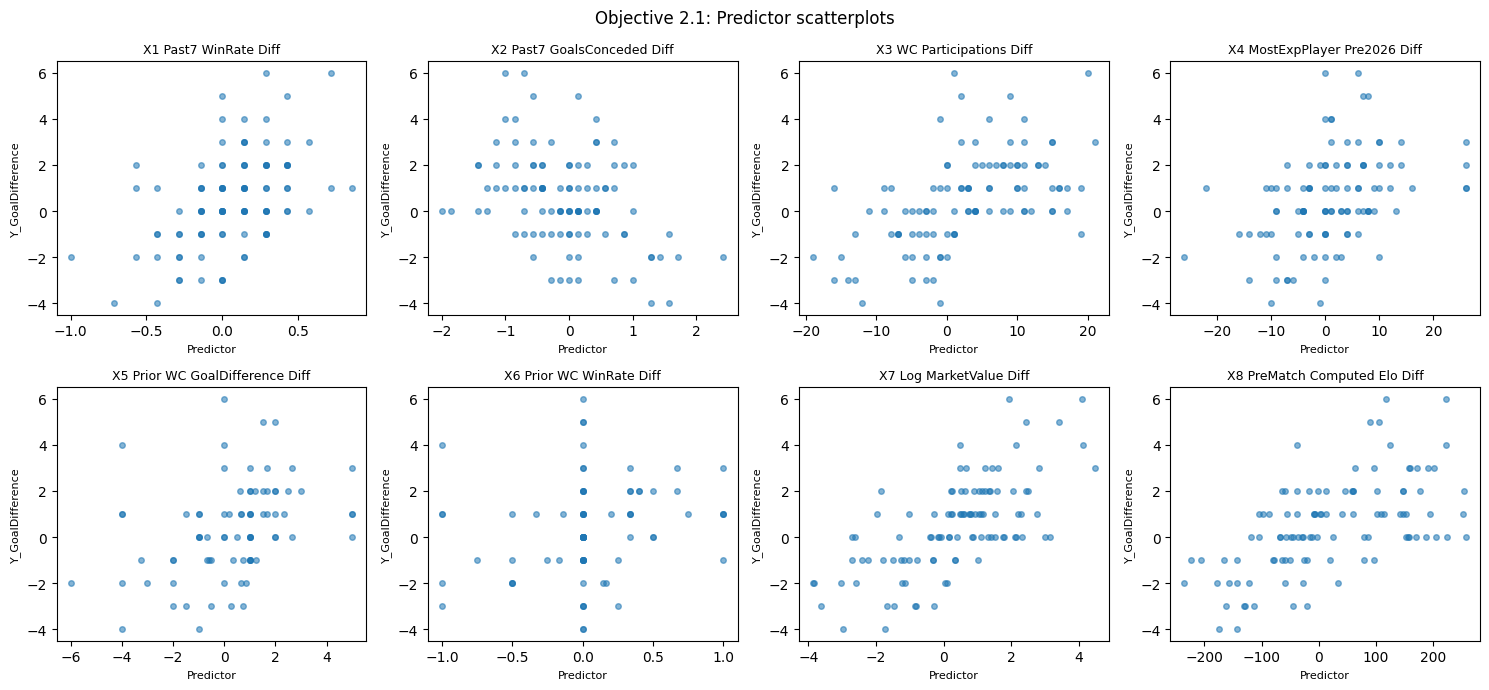

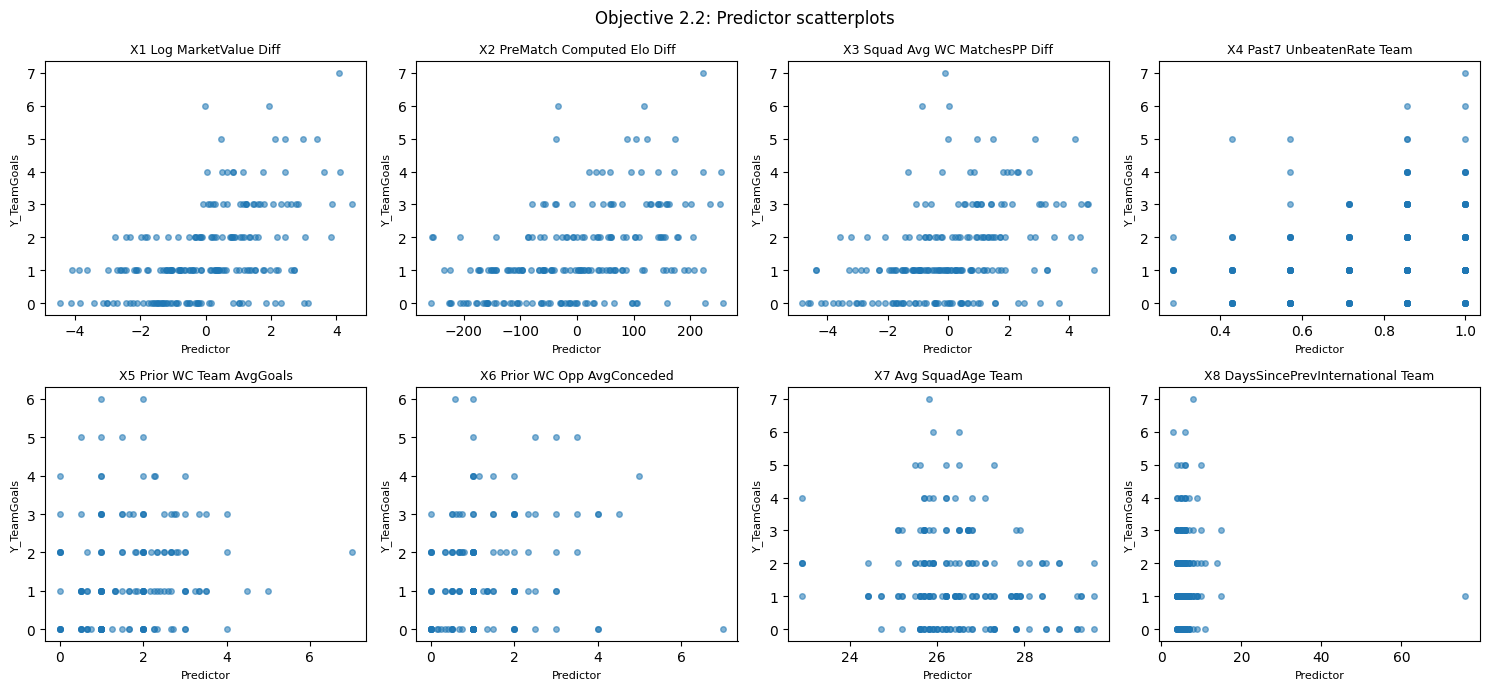

In [4]:
display(df21[x21 + [y21]].describe().round(2))
display(df22[x22 + [y22]].describe().round(2))

def scatterplots(df, features, target, title):
    fig, axes = plt.subplots(2, 4, figsize=(15, 7))
    for ax, col in zip(axes.flat, features):
        ax.scatter(df[col], df[target], alpha=0.55, s=16)
        ax.set_title(col.replace('_', ' '), fontsize=9)
        ax.set_xlabel('Predictor', fontsize=8)
        ax.set_ylabel(target, fontsize=8)
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()

scatterplots(df21, x21, y21, 'Objective 2.1: Predictor scatterplots')
scatterplots(df22, x22, y22, 'Objective 2.2: Predictor scatterplots')

## 5. Correlation check

This helps spot predictors that are closely related. Correlation does not prove that a variable is useful for prediction.

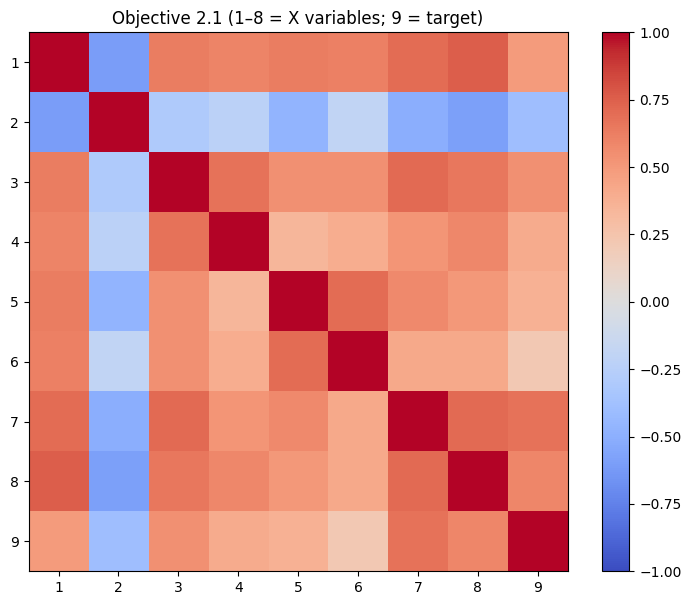

,Correlation with target
X1_Past7_WinRate_Diff,0.489
X2_Past7_GoalsConceded_Diff,-0.393
X3_WC_Participations_Diff,0.546
X4_MostExpPlayer_Pre2026_Diff,0.406
X5_Prior_WC_GoalDifference_Diff,0.371
X6_Prior_WC_WinRate_Diff,0.212
X7_Log_MarketValue_Diff,0.676
X8_PreMatch_Computed_Elo_Diff,0.589


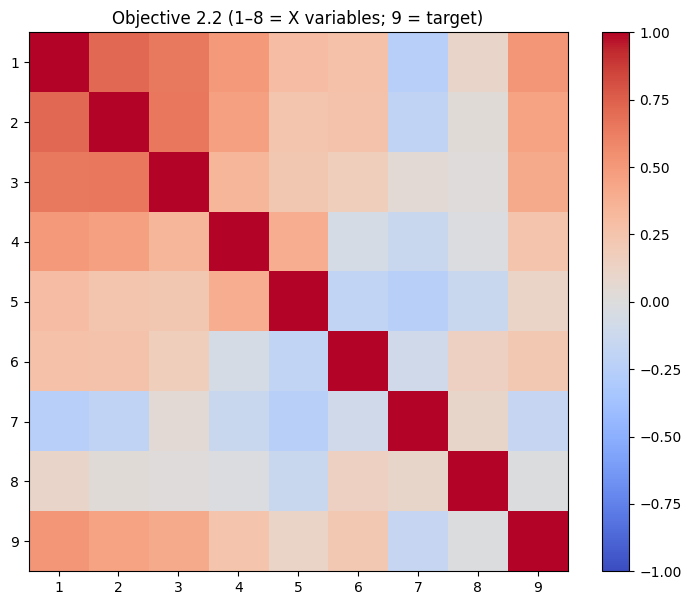

,Correlation with target
X1_Log_MarketValue_Diff,0.514
X2_PreMatch_Computed_Elo_Diff,0.449
X3_Squad_Avg_WC_MatchesPP_Diff,0.411
X4_Past7_UnbeatenRate_Team,0.247
X5_Prior_WC_Team_AvgGoals,0.111
X6_Prior_WC_Opp_AvgConceded,0.215
X7_Avg_SquadAge_Team,-0.171
X8_DaysSincePrevInternational_Team,-0.013


In [5]:
def correlations(df, features, target, title):
    corr = df[features + [target]].corr()
    fig, ax = plt.subplots(figsize=(9, 7))
    im = ax.imshow(corr, vmin=-1, vmax=1, cmap='coolwarm')
    ax.set_xticks(range(len(corr.columns)), [str(i+1) for i in range(len(corr))])
    ax.set_yticks(range(len(corr.columns)), [str(i+1) for i in range(len(corr))])
    ax.set_title(title + ' (1–8 = X variables; 9 = target)')
    fig.colorbar(im, ax=ax)
    plt.show()
    display(corr[target].drop(target).to_frame('Correlation with target').round(3))

correlations(df21, x21, y21, 'Objective 2.1')
correlations(df22, x22, y22, 'Objective 2.2')

## 6. Build and test the regression models

I compare 60/40, 70/30 and 80/20 random splits. Both team rows in Objective 2.2 must stay in the same split, so splitting is done by **match ID**. I also use a chronological 80/20 split as the final test because we should predict later matches using earlier ones. Missing X values are filled with medians calculated on the training portion only.

In [6]:
def run_model(data, features, target, test_size=0.2, chronological=False):
    matches = data[['Match_ID', 'Date']].drop_duplicates('Match_ID').sort_values(['Date','Match_ID'])
    if chronological:
        cut = int(len(matches) * (1 - test_size))
        train_ids = set(matches.iloc[:cut]['Match_ID'])
        test_ids = set(matches.iloc[cut:]['Match_ID'])
    else:
        train_ids, test_ids = train_test_split(matches['Match_ID'].to_numpy(), test_size=test_size, random_state=42)
        train_ids, test_ids = set(train_ids), set(test_ids)

    train = data[data['Match_ID'].isin(train_ids)].copy()
    test = data[data['Match_ID'].isin(test_ids)].copy()
    # A match must never appear in both sets.
    assert not (train_ids & test_ids)
    medians = train[features].median().fillna(0)
    X_train = train[features].fillna(medians)
    X_test = test[features].fillna(medians)
    y_train, y_test = train[target], test[target]
    # Targets cannot be filled because they are the actual results.
    valid_train = y_train.notna()
    valid_test = y_test.notna()
    model = LinearRegression()
    model.fit(X_train.loc[valid_train], y_train.loc[valid_train])
    prediction = model.predict(X_test.loc[valid_test])
    actual = y_test.loc[valid_test]
    metrics = {
        'Train rows': int(valid_train.sum()), 'Test rows': int(valid_test.sum()),
        'MAE': mean_absolute_error(actual, prediction),
        'RMSE': np.sqrt(mean_squared_error(actual, prediction)),
        'R2': r2_score(actual, prediction)
    }
    return metrics, model, actual.to_numpy(), prediction, train, test, medians

splits = [('60/40',0.4,False), ('70/30',0.3,False), ('80/20',0.2,False),
          ('Chronological 80/20',0.2,True)]
results = []
final_models = {}
for label, data, cols, target in [('2.1',df21,x21,y21), ('2.2',df22,x22,y22)]:
    for split_name, size, chrono in splits:
        metrics, model, actual, pred, train, test, medians = run_model(data,cols,target,size,chrono)
        results.append({'Objective':label,'Split':split_name,**metrics})
        if chrono:
            final_models[label] = (model,actual,pred,train,test,medians,cols,target)

scores = pd.DataFrame(results)
display(scores.round(3))

,Objective,Split,Train rows,Test rows,MAE,RMSE,R2
0,2.1,60/40,62,42,1.293,1.659,0.421
1,2.1,70/30,72,32,1.297,1.690,0.421
2,2.1,80/20,83,21,1.431,1.843,0.384
3,2.1,Chronological 80/20,83,21,1.058,1.349,0.224
4,2.2,60/40,124,84,0.924,1.159,0.280
5,2.2,70/30,144,64,0.936,1.196,0.296
6,2.2,80/20,166,42,0.954,1.202,0.327
7,2.2,Chronological 80/20,166,42,0.932,1.258,0.083


## 7. Final test plots and residuals

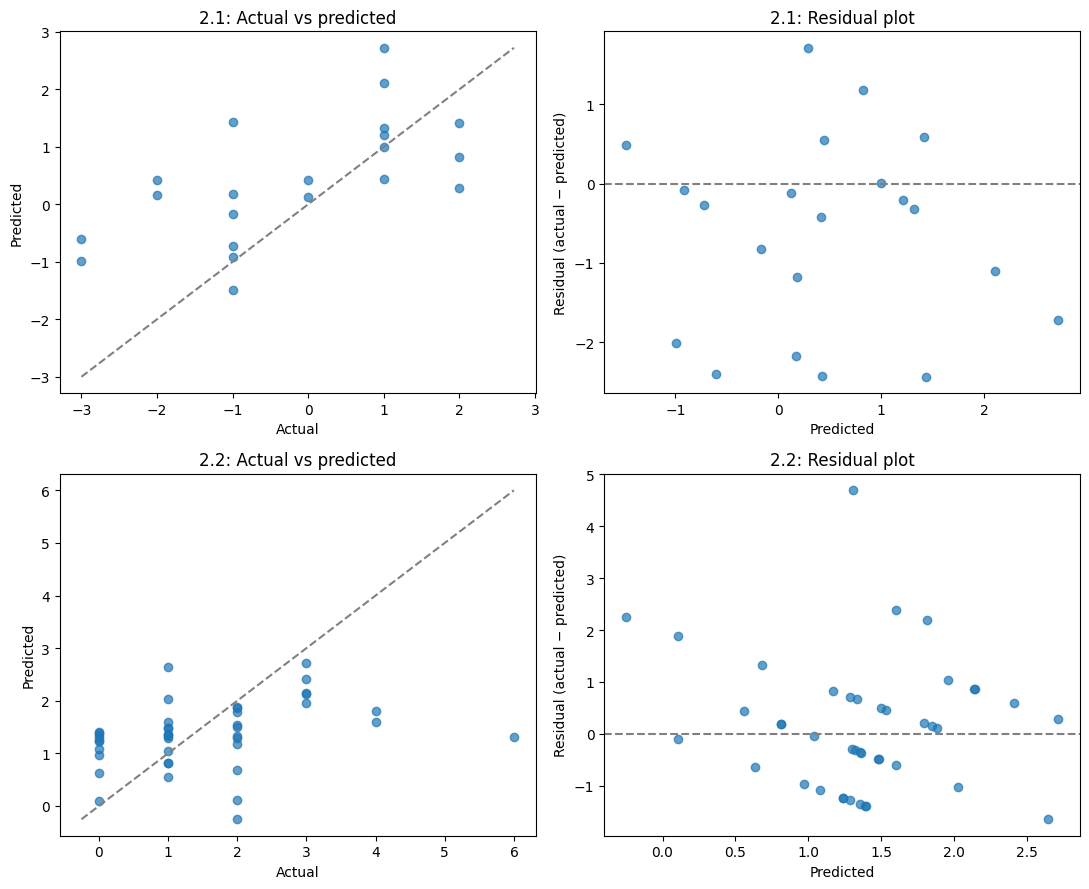

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for i, label in enumerate(['2.1','2.2']):
    model, actual, pred, train, test, medians, cols, target = final_models[label]
    residuals = actual - pred
    ax = axes[i,0]
    ax.scatter(actual,pred,alpha=0.7)
    bounds = [min(actual.min(),pred.min()), max(actual.max(),pred.max())]
    ax.plot(bounds,bounds,'--',color='grey')
    ax.set(xlabel='Actual',ylabel='Predicted',title=f'{label}: Actual vs predicted')
    ax = axes[i,1]
    ax.scatter(pred,residuals,alpha=0.7)
    ax.axhline(0,linestyle='--',color='grey')
    ax.set(xlabel='Predicted',ylabel='Residual (actual − predicted)',title=f'{label}: Residual plot')
fig.tight_layout()
plt.show()

## 8. Final checks and interpretation

I check whether the errors are centred around zero, whether their spread changes, and whether some predictors are strongly correlated. The regression output should be interpreted using the **test results**, not training accuracy.

The predicted outcomes are not guaranteed to be accurate. In particular, goals are discrete counts, while ordinary linear regression predicts continuous values. The main purpose here is to meet the assignment's linear regression requirement and evaluate how well it works.

In [8]:
for label in ['2.1','2.2']:
    model, actual, pred, train, test, medians, cols, target = final_models[label]
    residuals = actual - pred
    print(f'\nObjective {label}:')
    print('Test residual mean:', round(float(residuals.mean()), 3))
    print('Test residual standard deviation:', round(float(residuals.std()), 3))
    print('Maximum absolute predictor correlation:', round(float(train[cols].corr().abs().where(~np.eye(len(cols),dtype=bool)).max().max()),3))
    print('Regression coefficients:')
    display(pd.DataFrame({'Variable':cols, 'Coefficient':model.coef_}).round(3))
print('\nData still needs pre-match verification for squad experience and market values.')


Objective 2.1:
Test residual mean: -0.629
Test residual standard deviation: 1.193
Maximum absolute predictor correlation: 0.743
Regression coefficients:


,Variable,Coefficient
0,X1_Past7_WinRate_Diff,0.109
1,X2_Past7_GoalsConceded_Diff,-0.084
2,X3_WC_Participations_Diff,0.030
3,X4_MostExpPlayer_Pre2026_Diff,0.003
4,X5_Prior_WC_GoalDifference_Diff,0.053
5,X6_Prior_WC_WinRate_Diff,-0.690
6,X7_Log_MarketValue_Diff,0.490
7,X8_PreMatch_Computed_Elo_Diff,0.003



Objective 2.2:
Test residual mean: 0.154
Test residual standard deviation: 1.248
Maximum absolute predictor correlation: 0.708
Regression coefficients:


,Variable,Coefficient
0,X1_Log_MarketValue_Diff,0.274
1,X2_PreMatch_Computed_Elo_Diff,0.002
2,X3_Squad_Avg_WC_MatchesPP_Diff,0.095
3,X4_Past7_UnbeatenRate_Team,-0.341
4,X5_Prior_WC_Team_AvgGoals,-0.097
5,X6_Prior_WC_Opp_AvgConceded,0.044
6,X7_Avg_SquadAge_Team,-0.112
7,X8_DaysSincePrevInternational_Team,-0.011



Data still needs pre-match verification for squad experience and market values.
